In [25]:
import pandas as pd
import duckdb as db
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("data/Binding_of_Isaac_stats.csv", sep=";")
df

,id,Character,victory,cause of loss,floor,time,difficulty,Ending goal,boss rush,Hush beaten,Delirium beaten,Item total,HP up,DMG up,Tears up,Speed up,Range up,Shot Speed up,Luck up
0,1,Isaac,False,e,3,00:08:24,N,21,n,n,n,6,1,1,0,1,0,1,1
1,1,Isaac,True,n,10,00:36:47,N,21,n,n,y,27,4,5,5,1,3,4,1
2,1,Isaac,False,r,6,00:20:39,N,22,n,n,n,19,1,2,1,1,3,1,1
3,1,Isaac,False,e,6,00:19:53,N,22,n,n,n,13,3,1,3,0,2,1,0
4,1,Isaac,True,n,15,00:35:16,N,22,n,n,n,25,6,5,3,3,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,10,Lilith,False,b,15,00:29:29,N,22,n,n,n,17,3,0,0,3,1,0,0
96,10,Lilith,True,n,15,00:34:11,N,22,n,n,n,19,2,0,3,2,2,1,0
97,10,Lilith,False,b,9,00:31:48,N,15,y,n,n,15,0,0,1,2,2,0,1
98,10,Lilith,True,n,11,00:32:11,N,15,y,y,n,31,3,6,2,1,3,1,0


doing value counts and stuff

In [8]:
df["Delirium beaten"].value_counts()

Delirium beaten
n    93
y     7
Name: count, dtype: int64

In [9]:
df["Hush beaten"].value_counts()

Hush beaten
n    93
y     7
Name: count, dtype: int64

In [10]:
df["victory"].value_counts()

victory
False    60
True     40
Name: count, dtype: int64

In [11]:
df["Character"].unique()

<ArrowStringArray>
[      'Isaac',   'Magdalene',         'Eve',         '???',      'Samson',
     'Lazarus', 'Jacob+Essau',      'Azazel',        'Eden',      'Lilith']
Length: 10, dtype: str

In [13]:
df["cause of loss"].value_counts()
#n = no loss
#b = died to a boss
#e = died to an enemy
#o = died to an obstacle
#r = reset the run

cause of loss
n    40
b    32
e    18
o     8
r     2
Name: count, dtype: int64

things that need to be done,

column for time intervals, 
drop the difficulty column, 
figure out how to graph the stat up columns with an item total for at least 1 character (lazarus?), 
a graph for each stat up column? (too much?), 
pie chart for cause of loss, 
pie chart for win rate

In [23]:
snake_case_df = df.rename({'cause of loss': 'cause_of_loss', 
                           'Ending goal': 'ending_goal', 
                           'boss rush': 'boss_rush',
                           'Hush beaten': 'hush_beaten',
                           'Delirium beaten': 'delirium_beaten',
                           'Item total': 'item_total',
                           'HP up': 'hp_up',
                           'DMG up': 'dmg_up',
                           'Tears up': 'tears_up',
                           'Speed up': 'speed_up',
                           'Range up': 'range_up',
                           'Shot Speed up': 'shot_speed_up',
                           'Luck up': 'luck_up',
                           'Character': 'character'}, axis=1)
snake_case_df

,id,character,victory,cause_of_loss,floor,time,difficulty,ending_goal,boss_rush,hush_beaten,delirium_beaten,item_total,hp_up,dmg_up,tears_up,speed_up,range_up,shot_speed_up,luck_up
0,1,Isaac,False,e,3,00:08:24,N,21,n,n,n,6,1,1,0,1,0,1,1
1,1,Isaac,True,n,10,00:36:47,N,21,n,n,y,27,4,5,5,1,3,4,1
2,1,Isaac,False,r,6,00:20:39,N,22,n,n,n,19,1,2,1,1,3,1,1
3,1,Isaac,False,e,6,00:19:53,N,22,n,n,n,13,3,1,3,0,2,1,0
4,1,Isaac,True,n,15,00:35:16,N,22,n,n,n,25,6,5,3,3,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,10,Lilith,False,b,15,00:29:29,N,22,n,n,n,17,3,0,0,3,1,0,0
96,10,Lilith,True,n,15,00:34:11,N,22,n,n,n,19,2,0,3,2,2,1,0
97,10,Lilith,False,b,9,00:31:48,N,15,y,n,n,15,0,0,1,2,2,0,1
98,10,Lilith,True,n,11,00:32:11,N,15,y,y,n,31,3,6,2,1,3,1,0


In [24]:
full_words = db.sql("""--sql
SELECT
    * EXCLUDE(cause_of_loss),
    CASE
        WHEN cause_of_loss = 'r' THEN 'reset'
        WHEN cause_of_loss = 'o' THEN 'obstacle'
        WHEN cause_of_loss = 'n' THEN 'no'
        WHEN cause_of_loss = 'e' THEN 'enemy'
        WHEN cause_of_loss = 'b' THEN 'boss'
    END AS cause_of_loss
FROM snake_case_df
""").df()
full_words

,id,character,victory,floor,time,difficulty,ending_goal,boss_rush,hush_beaten,delirium_beaten,item_total,hp_up,dmg_up,tears_up,speed_up,range_up,shot_speed_up,luck_up,cause_of_loss
0,1,Isaac,False,3,00:08:24,N,21,n,n,n,6,1,1,0,1,0,1,1,enemy
1,1,Isaac,True,10,00:36:47,N,21,n,n,y,27,4,5,5,1,3,4,1,no
2,1,Isaac,False,6,00:20:39,N,22,n,n,n,19,1,2,1,1,3,1,1,reset
3,1,Isaac,False,6,00:19:53,N,22,n,n,n,13,3,1,3,0,2,1,0,enemy
4,1,Isaac,True,15,00:35:16,N,22,n,n,n,25,6,5,3,3,1,0,1,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,10,Lilith,False,15,00:29:29,N,22,n,n,n,17,3,0,0,3,1,0,0,boss
96,10,Lilith,True,15,00:34:11,N,22,n,n,n,19,2,0,3,2,2,1,0,no
97,10,Lilith,False,9,00:31:48,N,15,y,n,n,15,0,0,1,2,2,0,1,boss
98,10,Lilith,True,11,00:32:11,N,15,y,y,n,31,3,6,2,1,3,1,0,no


don't run this yet

In [ ]:
data_model_df.to_csv("tempname")

## graph of victories per character

In [ ]:
wins = snake_case_df.groupby("character")["victory"].sum().sort_values(ascending=False)
wins #getting total of the values for the victories

character
Lazarus        7
Isaac          7
Azazel         6
Lilith         5
Magdalene      5
Eve            3
Samson         3
???            2
Eden           2
Jacob+Essau    0
Name: victory, dtype: int64

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Lazarus'),
  Text(1, 0, 'Isaac'),
  Text(2, 0, 'Azazel'),
  Text(3, 0, 'Lilith'),
  Text(4, 0, 'Magdalene'),
  Text(5, 0, 'Eve'),
  Text(6, 0, 'Samson'),
  Text(7, 0, '???'),
  Text(8, 0, 'Eden'),
  Text(9, 0, 'Jacob+Essau')])

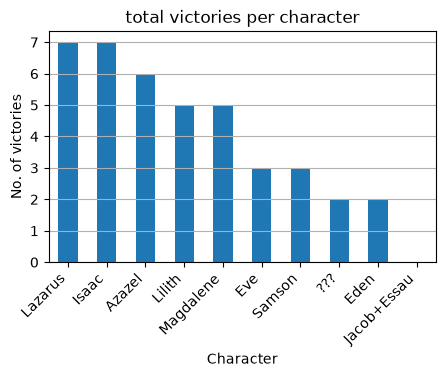

In [35]:
ax = wins.plot.bar(figsize=[5,3])
ax.grid(axis="y")
plt.title("total victories per character")
plt.xlabel("Character")
plt.ylabel("No. of victories")
plt.xticks(rotation=45, ha="right")


## graph total of items per characters

In [36]:
items = snake_case_df.groupby("character")["item_total"].sum().sort_values(ascending=False)
items

character
Lazarus        231
Magdalene      230
Azazel         216
Isaac          213
Eden           187
Jacob+Essau    185
Lilith         184
Eve            178
Samson         162
???            142
Name: item_total, dtype: int64

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Lazarus'),
  Text(1, 0, 'Magdalene'),
  Text(2, 0, 'Azazel'),
  Text(3, 0, 'Isaac'),
  Text(4, 0, 'Eden'),
  Text(5, 0, 'Jacob+Essau'),
  Text(6, 0, 'Lilith'),
  Text(7, 0, 'Eve'),
  Text(8, 0, 'Samson'),
  Text(9, 0, '???')])

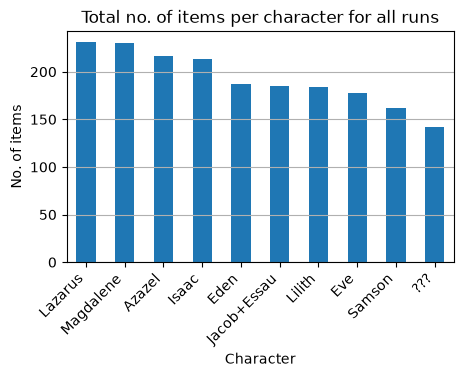

In [37]:
ax = items.plot.bar(figsize=(5,3))
ax.grid(axis="y")
plt.title("Total no. of items per character for all runs")
plt.xlabel("Character")
plt.ylabel("No. of items")
plt.xticks(rotation=45, ha="right")
